# **Assignment**

In [89]:
# Step 1
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
print("Libraries imported successfully")


Libraries imported successfully


Import and Read **Dataset**

In [90]:
#step 2
df = pd.read_csv('/content/house_price_prediction_dataset.csv')
df

,Area_sqft,Bedrooms,Bathrooms,Age_years,Distance_to_city_km,Parking_Spaces,Price_Lakh_INR
0,723,2,2,0,2.7,2,52.50
1,2435,4,4,20,21.2,2,121.36
2,2137,4,4,4,2.3,1,134.66
3,1597,4,4,20,7.7,2,97.78
4,1582,3,2,19,9.0,0,81.25
...,...,...,...,...,...,...,...
195,719,1,1,25,14.5,0,21.95
196,1356,2,2,11,20.0,2,72.25
197,795,2,2,15,19.8,1,35.89
198,1347,3,2,1,11.5,0,67.50


Inspect the Dataset

In [91]:
#Step 3
print("Print first five rows:")
print(df.head())

print("Print last five rows:")
print(df.tail())

print("Shape of the dataset")
print(df.shape)

print("Print number of rows:")
print(df.shape[0])

print("Number of columns:")
print(df.shape[1])

print("Information of dataset:")
print(df.info())

print("Description of the dataset:")
print(df.describe())

print("Column names:")
print(df.columns)

Print first five rows:
   Area_sqft  Bedrooms  Bathrooms  Age_years  Distance_to_city_km  \
0        723         2          2          0                  2.7   
1       2435         4          4         20                 21.2   
2       2137         4          4          4                  2.3   
3       1597         4          4         20                  7.7   
4       1582         3          2         19                  9.0   

   Parking_Spaces  Price_Lakh_INR  
0               2           52.50  
1               2          121.36  
2               1          134.66  
3               2           97.78  
4               0           81.25  
Print last five rows:
     Area_sqft  Bedrooms  Bathrooms  Age_years  Distance_to_city_km  \
195        719         1          1         25                 14.5   
196       1356         2          2         11                 20.0   
197        795         2          2         15                 19.8   
198       1347         3          2     

Check quality of the data

In [92]:
#step 4
print("Missing values:")
print(df.isnull().sum())

print("Duplicate values:")
print(df.duplicated().sum())

Missing values:
Area_sqft              0
Bedrooms               0
Bathrooms              0
Age_years              0
Distance_to_city_km    0
Parking_Spaces         0
Price_Lakh_INR         0
dtype: int64
Duplicate values:
0


## Data **visualisation**

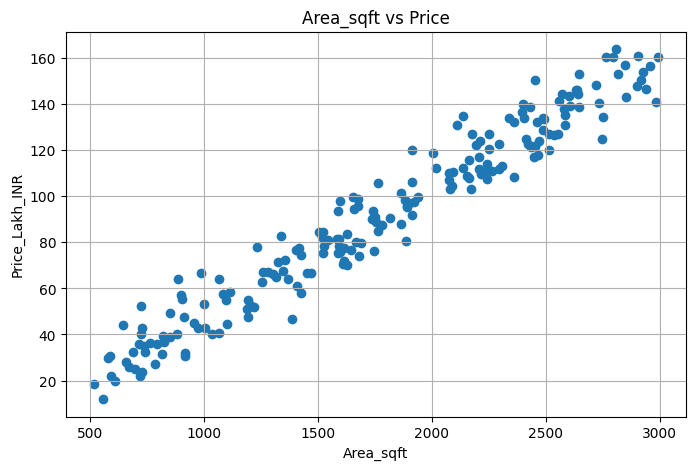

In [93]:
#step 5
plt.figure(figsize=(8,5))
plt.scatter(df["Area_sqft"],df["Price_Lakh_INR"])
plt.xlabel("Area_sqft")
plt.ylabel("Price_Lakh_INR")
plt.title("Area_sqft vs Price")
plt.grid(True)
plt.show()

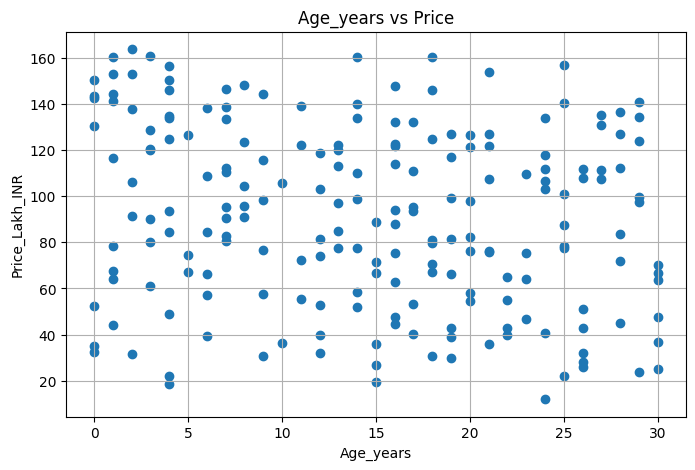

In [94]:
plt.figure(figsize=(8,5))
plt.scatter(df["Age_years"],df["Price_Lakh_INR"])
plt.xlabel("Age_years")
plt.ylabel("Price_Lakh_INR")
plt.title("Age_years vs Price")
plt.grid(True)
plt.show()

Prepare data for machine learning

In [95]:
x = df[["Age_years","Area_sqft"]]
y = df["Price_Lakh_INR"]

print("features (x):")
print(x)

print("Target (y):")
print(y)

features (x):
     Age_years  Area_sqft
0            0        723
1           20       2435
2            4       2137
3           20       1597
4           19       1582
..         ...        ...
195         25        719
196         11       1356
197         15        795
198          1       1347
199          3       2905

[200 rows x 2 columns]
Target (y):
0       52.50
1      121.36
2      134.66
3       97.78
4       81.25
        ...  
195     21.95
196     72.25
197     35.89
198     67.50
199    160.56
Name: Price_Lakh_INR, Length: 200, dtype: float64


In [96]:
# step 6
#Train test split
x_train,x_test,y_train,y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples",len(x_train))
print("Testing samples",len(x_test))

Training samples 160
Testing samples 40


In [97]:
#create the model

model = LinearRegression()

In [98]:
#train the model

model.fit(x_train,y_train)

LinearRegression()

In [99]:
# Inspect learned parameters

print("Coefficients")
print(model.coef_)

print("Intercept")
print(model.intercept_)

Coefficients
[-0.3261      0.05464492]
Intercept
-1.139288317588111


In [100]:
# Predict the text data
y_pred = model.predict(x_test)

print("Actual values:")
print(y_test.values)

print("Predicted values:")
print(y_pred)

Actual values:
[ 51.9  117.98  70.   105.74  99.66  97.53  95.88  36.26 113.84 153.74
 160.19  93.68 126.36 106.    31.95  55.52  88.03 160.21  57.16  32.25
 145.96  87.36 127.02  66.56  64.93 163.68 109.88  74.29 120.03  42.65
  35.16 143.47  19.62  79.82 144.24 133.54  67.23  30.02  80.87  71.28]
Predicted values:
[ 61.01675609 125.73403362  77.93034772  91.93870145  95.2510171
  94.43134334  87.72750379  37.40307366 116.15701699 151.95828556
 149.57316401  88.56310309 130.86357785 102.63494927  40.38221128
  44.61797229  95.61052796 147.02785645  46.13918246  36.56570485
 141.70960439  88.14009979 129.3476762   69.35109565  63.48993342
 151.59679547 107.68351575  75.15386422 102.41813911  32.33702186
  39.02472614 140.93749752  27.2479665   85.28617754 140.18839422
 132.75314641  61.84350788  24.19492913  77.4173094   66.37372753]


In [101]:
#Compare Actual and predicted values
comparison_df = pd.DataFrame({
    "Actual":y_test,
   "Predicted":y_pred
    })
print(comparison_df)

     Actual   Predicted
95    51.90   61.016756
15   117.98  125.734034
30    70.00   77.930348
158  105.74   91.938701
128   99.66   95.251017
115   97.53   94.431343
69    95.88   87.727504
170   36.26   37.403074
174  113.84  116.157017
45   153.74  151.958286
66   160.19  149.573164
182   93.68   88.563103
165  126.36  130.863578
78   106.00  102.634949
186   31.95   40.382211
177   55.52   44.617972
56    88.03   95.610528
152  160.21  147.027856
82    57.16   46.139182
68    32.25   36.565705
124  145.96  141.709604
16    87.36   88.140100
148  127.02  129.347676
93    66.56   69.351096
65    64.93   63.489933
60   163.68  151.596795
84   109.88  107.683516
67    74.29   75.153864
125  120.03  102.418139
132   42.65   32.337022
9     35.16   39.024726
18   143.47  140.937498
55    19.62   27.247967
75    79.82   85.286178
150  144.24  140.188394
104  133.54  132.753146
135   67.23   61.843508
137   30.02   24.194929
164   80.87   77.417309
76    71.28   66.373728


In [102]:
#Mean Absolute error
mae = mean_absolute_error(y_test,y_pred)
print("Mean Absolute Error:",mae)

Mean Absolute Error: 5.927456378571952


In [103]:
#Mean Squared error
mse = mean_squared_error(y_test,y_pred)
print("Mean Squared Error:",mse)

Mean Squared Error: 51.52983013278638


In [104]:
#Root Mean Squared Error
rmse = np.sqrt(mse)
print("Root Mean Squared Error:",rmse)

Root Mean Squared Error: 7.17842811016356


In [105]:
#R2 Score
r2=r2_score(y_test,y_pred)
print("R2 Score:",r2)


R2 Score: 0.9688301060124166


In [106]:
#predict price of a house
new_house_price = pd.DataFrame({
    "Age_years" : [10],
    "Area_sqft" : [1000]
})

new_price = model.predict(new_house_price)

print("Area_sqft",new_house_price["Area_sqft"].values[0])
print("Age_years:",new_house_price["Age_years"].values[0])
print("new_price:",new_price[0],2)

Area_sqft 1000
Age_years: 10
new_price: 50.24462930192783 2


In [107]:
import joblib
import sklearn

# Save the trained model
joblib.dump(model,"house_price_prediction_model.pkl")

# Check the installed scikit-learn version
print("Scikit-learn version:",sklearn.__version__)

print("Model saved successfully")

Scikit-learn version: 1.6.1
Model saved successfully


In [108]:
from google.colab import files

# Download the trained model
files.download("house_price_prediction_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>